<a href="https://colab.research.google.com/github/kkavyasahithi-web/Drone--Crop-Health-Monitoring/blob/main/Drone%20_Crop_Health_Monitoring.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import load_sample_image

# 1. Load built-in sample image and resize to a clean base canvas
base_img = load_sample_image("china.jpg").astype(np.float32)  # (427, 640, 3)
h_full, w_full, _ = base_img.shape

rng = np.random.default_rng(42)
num_plots = 60
plot_size = 128

plots = []  # List of dicts holding Red, Green, NIR, true_stress_mask, yield_kg_ha, disease_score

for i in range(num_plots):
  # Crop random patch from base image to vary spatial texture across plots
  y0 = rng.integers(0, h_full - plot_size)
  x0 = rng.integers(0, w_full - plot_size)
  patch = base_img[y0 : y0 + plot_size, x0 : x0 + plot_size]

  # Assign a plot health regime (healthy, moderate stress, severe stress/disease)
  health_level = rng.uniform(0.25, 0.95)

  # Normalize channels to [0, 1]
  norm_r = patch[:, :, 0] / 255.0
  norm_g = patch[:, :, 1] / 255.0
  norm_b = patch[:, :, 2] / 255.0

  # Simulate Red, Green, and NIR reflectance bands
  red = np.clip(0.08 + 0.18 * (1.0 - health_level) + 0.05 * norm_r, 0.01, 0.9)
  green = np.clip(0.07 + 0.08 * health_level + 0.05 * norm_g, 0.01, 0.9)
  nir = np.clip(0.18 + 0.45 * health_level + 0.08 * norm_b, 0.02, 0.95)

  # Inject 1 to 3 localized stress/disease patches into the plot
  stress_mask = np.zeros((plot_size, plot_size), dtype=bool)
  for _ in range(rng.integers(1, 4)):
    cy, cx = rng.integers(20, plot_size - 20, size=2)
    rad = rng.integers(10, 26)
    yy, xx = np.ogrid[:plot_size, :plot_size]
    patch_mask = ((yy - cy) ** 2 + (xx - cx) ** 2) <= rad**2
    stress_mask |= patch_mask

    # Inside stress patches: NIR drops (cell structure damage) and Red rises (less chlorophyll absorption)
    nir[patch_mask] *= rng.uniform(0.35, 0.60)
    red[patch_mask] = np.clip(red[patch_mask] * rng.uniform(1.3, 1.8), 0.01, 0.9)

  # Ground-truth labels correlated with crop vigor and stress area
  stress_fraction = stress_mask.mean()
  disease_score = np.clip(
      stress_fraction * 140 + (1.0 - health_level) * 35 + rng.normal(0, 4),
      0,
      100,
  )
  yield_kg_ha = np.clip(
      2200 + 4800 * health_level - 3500 * stress_fraction + rng.normal(0, 220),
      800,
      8000,
  )

  plots.append({
      "plot_id": f"PLOT_{i+1:02d}",
      "red": red,
      "green": green,
      "nir": nir,
      "gt_stress_mask": stress_mask,
      "gt_stress_fraction": stress_fraction,
      "disease_score": disease_score,
      "yield_kg_ha": yield_kg_ha,
  })

print(
    f"Generated {len(plots)} multispectral drone plots ({plot_size}x{plot_size}"
    " px each)."
)

Generated 60 multispectral drone plots (128x128 px each).


# New Section

In [ ]:
def compute_vegetation_indices(red, green, nir):
  eps = 1e-6
  ndvi = np.clip((nir - red) / (nir + red + eps), -1.0, 1.0)
  gndvi = np.clip((nir - green) / (nir + green + eps), -1.0, 1.0)
  return ndvi, gndvi


for p in plots:
  ndvi, gndvi = compute_vegetation_indices(p["red"], p["green"], p["nir"])
  p["ndvi"] = ndvi
  p["gndvi"] = gndvi
  p["mean_ndvi"] = float(np.mean(ndvi))
  p["mean_gndvi"] = float(np.mean(gndvi))

print("Sample Plot 1 -> Mean NDVI:", round(plots[0]["mean_ndvi"], 3),
      "| Mean GNDVI:", round(plots[0]["mean_gndvi"], 3))

Sample Plot 1 -> Mean NDVI: 0.308 | Mean GNDVI: 0.445


In [ ]:
STRESS_NDVI_THRESHOLD = 0.42

rows = []
for p in plots:
  pred_stress = p["ndvi"] < STRESS_NDVI_THRESHOLD
  gt_stress = p["gt_stress_mask"]

  tp = np.sum(pred_stress & gt_stress)
  fp = np.sum(pred_stress & (~gt_stress))
  fn = np.sum((~pred_stress) & gt_stress)

  precision = tp / (tp + fp + 1e-8)
  recall = tp / (tp + fn + 1e-8)
  iou = tp / (tp + fp + fn + 1e-8)

  p["pred_stress_mask"] = pred_stress
  p["pred_stress_fraction"] = float(np.mean(pred_stress))

  rows.append({
      "plot_id": p["plot_id"],
      "mean_ndvi": p["mean_ndvi"],
      "mean_gndvi": p["mean_gndvi"],
      "pred_stress_frac": p["pred_stress_fraction"],
      "gt_stress_frac": p["gt_stress_fraction"],
      "iou": iou,
      "precision": precision,
      "recall": recall,
      "disease_score": p["disease_score"],
      "yield_kg_ha": p["yield_kg_ha"],
  })

df = pd.DataFrame(rows)
print(df.head(10).to_string(index=False))
print(f"\nAverage Stress Mask IoU across plots: {df['iou'].mean():.3f}")

plot_id  mean_ndvi  mean_gndvi  pred_stress_frac  gt_stress_frac      iou  precision  recall  disease_score  yield_kg_ha
PLOT_01   0.307664    0.445258          0.179443        0.167603 0.934014   0.934014     1.0      42.479426  4459.136897
PLOT_02   0.548100    0.522259          0.155884        0.155884 1.000000   1.000000     1.0      25.192353  5887.844853
PLOT_03   0.492105    0.489001          0.180176        0.180176 1.000000   1.000000     1.0      31.948424  5199.918891
PLOT_04   0.450879    0.504344          0.214478        0.214478 1.000000   1.000000     1.0      40.136729  4963.509903
PLOT_05   0.541015    0.539723          0.054993        0.054993 1.000000   1.000000     1.0      22.652188  5386.398461
PLOT_06   0.454032    0.532746          0.076721        0.076721 1.000000   1.000000     1.0      26.316071  4953.949632
PLOT_07   0.243226    0.479900          1.000000        0.098877 0.098877   0.098877     1.0      36.824092  3806.268827
PLOT_08   0.407991    0.488487  

In [ ]:
pairs = [
    ("mean_ndvi", "yield_kg_ha", "Mean NDVI vs. Yield (kg/ha)"),
    ("pred_stress_frac", "yield_kg_ha", "Detected Stress % vs. Yield (kg/ha)"),
    ("pred_stress_frac", "disease_score", "Detected Stress % vs. Disease Score"),
    ("mean_ndvi", "disease_score", "Mean NDVI vs. Disease Score"),
]

for x_col, y_col, title in pairs:
  r, p_val = stats.pearsonr(df[x_col], df[y_col])
  rho, sp_val = stats.spearmanr(df[x_col], df[y_col])
  print(
      f"{title:42s} | Pearson r = {r:+.3f} (p={p_val:.2e}) | Spearman rho ="
      f" {rho:+.3f}"
  )

Mean NDVI vs. Yield (kg/ha)                | Pearson r = +0.961 (p=5.04e-34) | Spearman rho = +0.971
Detected Stress % vs. Yield (kg/ha)        | Pearson r = -0.822 (p=7.73e-16) | Spearman rho = -0.842
Detected Stress % vs. Disease Score        | Pearson r = +0.490 (p=7.05e-05) | Spearman rho = +0.784
Mean NDVI vs. Disease Score                | Pearson r = -0.708 (p=2.52e-10) | Spearman rho = -0.735


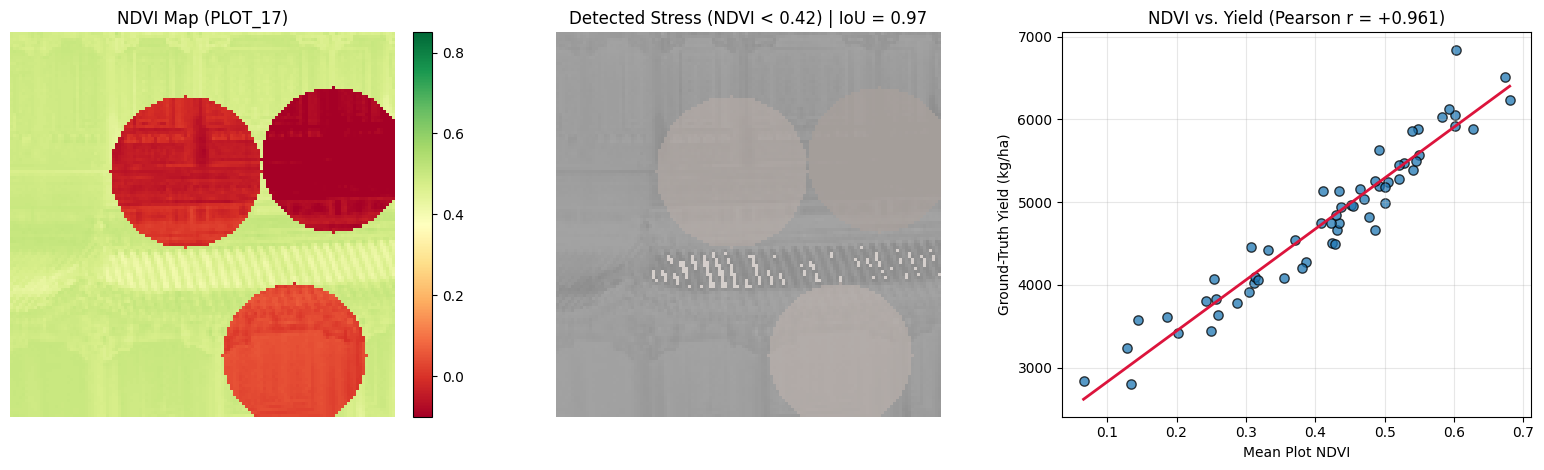

In [ ]:
# Pick a plot with clear stress patches for visual clarity
demo_plot = max(plots, key=lambda x: x["gt_stress_fraction"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Panel 1: NDVI heatmap
im0 = axes[0].imshow(demo_plot["ndvi"], cmap="RdYlGn", vmin=-0.1, vmax=0.85)
axes[0].set_title(f"NDVI Map ({demo_plot['plot_id']})")
axes[0].axis("off")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

# Panel 2: Detected stress mask overlaid on NDVI
axes[1].imshow(demo_plot["ndvi"], cmap="gray", vmin=-0.1, vmax=0.85)
overlay = np.ma.masked_where(
    ~demo_plot["pred_stress_mask"], demo_plot["pred_stress_mask"]
)
axes[1].imshow(overlay, cmap="Reds", alpha=0.65)
axes[1].set_title(
    f"Detected Stress (NDVI < {STRESS_NDVI_THRESHOLD}) | IoU ="
    f" {df.loc[df['plot_id']==demo_plot['plot_id'], 'iou'].values[0]:.2f}"
)
axes[1].axis("off")

# Panel 3: Mean NDVI vs Ground-Truth Yield with linear trendline
m, b = np.polyfit(df["mean_ndvi"], df["yield_kg_ha"], 1)
r_yield, _ = stats.pearsonr(df["mean_ndvi"], df["yield_kg_ha"])
axes[2].scatter(
    df["mean_ndvi"], df["yield_kg_ha"], alpha=0.75, edgecolor="k", s=45
)
x_line = np.linspace(df["mean_ndvi"].min(), df["mean_ndvi"].max(), 100)
axes[2].plot(x_line, m * x_line + b, color="crimson", linewidth=2)
axes[2].set_xlabel("Mean Plot NDVI")
axes[2].set_ylabel("Ground-Truth Yield (kg/ha)")
axes[2].set_title(f"NDVI vs. Yield (Pearson r = {r_yield:+.3f})")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Features derived from vegetation indices and detected stress regions
feature_cols = ["mean_ndvi", "mean_gndvi", "pred_stress_frac"]
target_col = "yield_kg_ha"

X = df[feature_cols]
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# 1. Baseline Linear Regression
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred_lin = lin_reg.predict(X_test)

# 2. Random Forest Regressor (captures non-linear stress/index interactions)
rf_reg = RandomForestRegressor(n_estimators=150, random_state=42)
rf_reg.fit(X_train, y_train)
y_pred_rf = rf_reg.predict(X_test)

for name, y_pred in [
    ("Linear Regression", y_pred_lin),
    ("Random Forest", y_pred_rf),
]:
  mae = mean_absolute_error(y_test, y_pred)
  rmse = np.sqrt(mean_squared_error(y_test, y_pred))
  r2 = r2_score(y_test, y_pred)
  print(
      f"{name:20s} | MAE: {mae:7.2f} kg/ha | RMSE: {rmse:7.2f} kg/ha | R2:"
      f" {r2:.4f}"
  )

# Feature importances from Random Forest for presentation talking points
importances = pd.Series(rf_reg.feature_importances_, index=feature_cols).sort_values(
    ascending=False
)
print("\nFeature Importances (Random Forest):")
print(importances.round(4).to_string())

Linear Regression    | MAE:  181.33 kg/ha | RMSE:  222.12 kg/ha | R2: 0.9116
Random Forest        | MAE:  206.64 kg/ha | RMSE:  263.83 kg/ha | R2: 0.8753

Feature Importances (Random Forest):
mean_ndvi           0.6602
pred_stress_frac    0.3080
mean_gndvi          0.0318


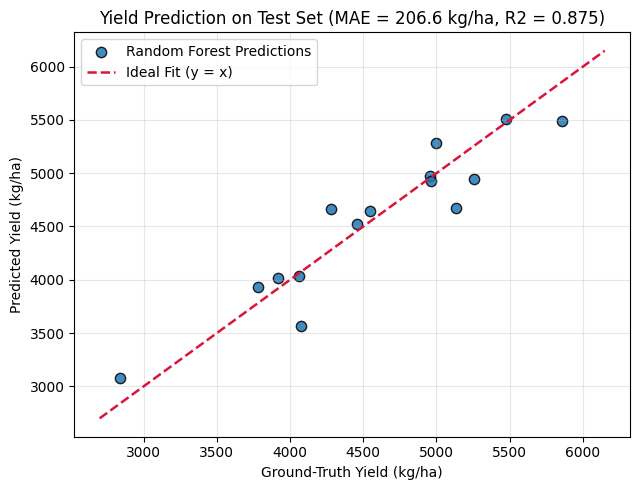

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 5))

ax.scatter(
    y_test,
    y_pred_rf,
    alpha=0.85,
    edgecolor="k",
    s=55,
    label="Random Forest Predictions",
)
min_val = min(y_test.min(), y_pred_rf.min()) * 0.95
max_val = max(y_test.max(), y_pred_rf.max()) * 1.05
ax.plot(
    [min_val, max_val],
    [min_val, max_val],
    "--",
    color="crimson",
    linewidth=1.8,
    label="Ideal Fit (y = x)",
)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)
ax.set_xlabel("Ground-Truth Yield (kg/ha)")
ax.set_ylabel("Predicted Yield (kg/ha)")
ax.set_title(f"Yield Prediction on Test Set (MAE = {mae_rf:.1f} kg/ha, R2 = {r2_rf:.3f})")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()